In [1]:
import warnings
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr, ttest_ind
from scipy.cluster.hierarchy import linkage, leaves_list
from sklearn.exceptions import ConvergenceWarning

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

In [2]:
GBM_DIV_CMAP = LinearSegmentedColormap.from_list("gbm_div", ["#6b6b6b", "white", "#D91F22"])
LGG_DIV_CMAP = LinearSegmentedColormap.from_list("lgg_div", ["#6b6b6b", "white", "#154DE6"])

warnings.filterwarnings("ignore", category=ConvergenceWarning)

sns.set_style("whitegrid")
np.random.seed(42)

kmf_gbm = KaplanMeierFitter()
kmf_lgg = KaplanMeierFitter()

# Exploratory Data Analysis

## Survival Outcomes

In [3]:
gbm_df = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_gbm\merged_df.csv")
lgg_df = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_lgg\merged_df.csv")

cgga_gbm_df = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\saved_models\cgga_gbm\validation_df.csv")
cgga_lgg_df = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\saved_models\cgga_lgg\validation_df.csv")

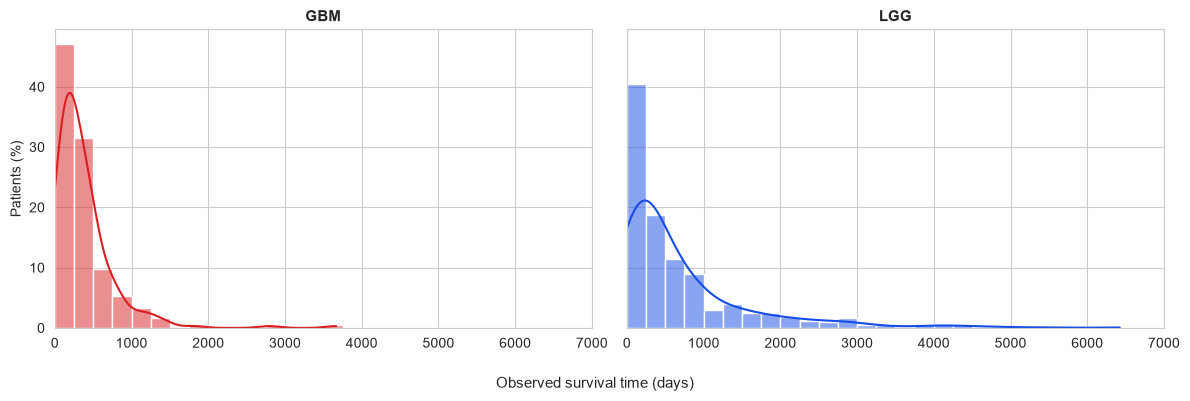

In [4]:
bin_edges = np.arange(0, 7000, 250)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, df, colour, label in [(axes[0], gbm_df, "#D91F22", "GBM"),
                              (axes[1], lgg_df, "#154DE6", "LGG")]:
    sns.histplot(df["time"], bins=bin_edges, stat="percent", kde=True, ax=ax, color=colour)
    ax.set_xlabel("")
    ax.set_xlim(0, 7000)
    ax.set_title(label, fontsize=11, fontweight='bold')

axes[0].set_ylabel("Patients (%)")
axes[1].set_ylabel("")
fig.supxlabel("Observed survival time (days)", fontsize=11)

plt.tight_layout()
plt.show()

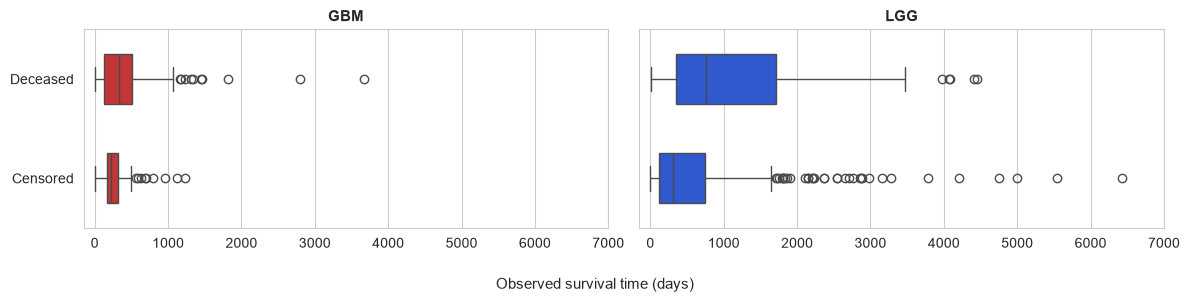

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharex=True, sharey=True)

for ax, df, colour, label in [(axes[0], gbm_df, "#D91F22", "GBM"),
                              (axes[1], lgg_df, "#154DE6", "LGG")]:
    plot_df = pd.DataFrame({
        "time": df["time"],
        "status": df["event"].map({1: "Deceased", 0: "Censored"}),
    })
    sns.boxplot(data=plot_df, x="time", y="status", order=["Deceased", "Censored"],
                color=colour, width=0.5, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xlim(-150, 7000)
    ax.set_title(label, fontsize=11, fontweight='bold')

fig.supxlabel("Observed survival time (days)", fontsize=11)

plt.tight_layout()
plt.show()

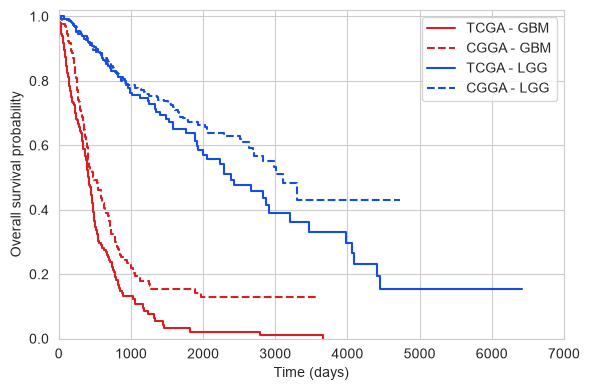

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))

for kmf, df, colour, style, label in [
    (kmf_gbm, gbm_df,      "#D91F22", "-",  "TCGA - GBM"),
    (kmf_gbm, cgga_gbm_df, "#D91F22", "--", "CGGA - GBM"),
    (kmf_lgg, lgg_df,      "#154DE6", "-",  "TCGA - LGG"),
    (kmf_lgg, cgga_lgg_df, "#154DE6", "--", "CGGA - LGG"),
]:
    kmf.fit(df["time"], df["event"], label=label)
    kmf.plot_survival_function(ax=ax, color=colour, linestyle=style, ci_show=False)

ax.set_xlabel("Time (days)")
ax.set_ylabel("Overall survival probability")
ax.set_xlim(0, 7000)
ax.set_ylim(0, 1.02)
ax.get_legend().set_title(None)
plt.tight_layout()
plt.show()

## Clinical

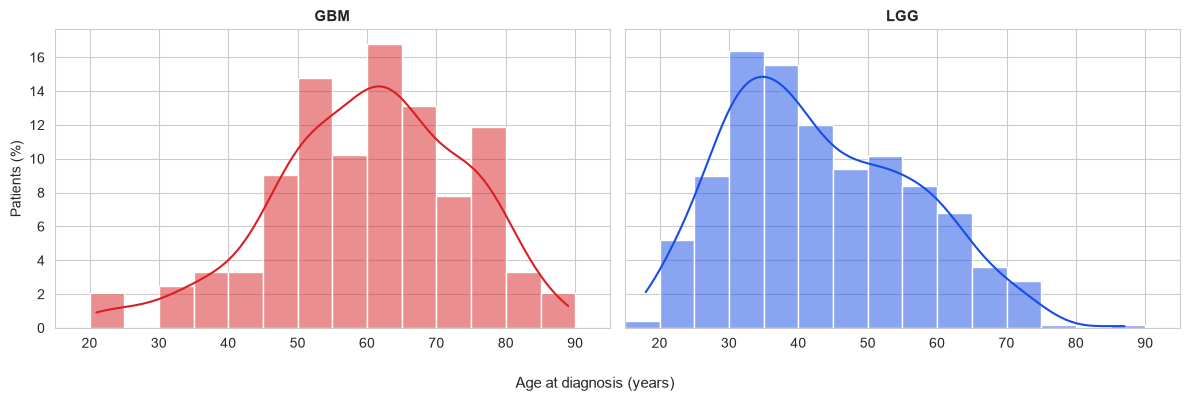

In [7]:
bin_edges = np.arange(15, 95, 5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, df, colour, label in [(axes[0], gbm_df, "#D91F22", "GBM"),
                              (axes[1], lgg_df, "#154DE6", "LGG")]:
    sns.histplot(df["age"], bins=bin_edges, stat="percent", kde=True, ax=ax, color=colour)
    ax.set_xlabel("")
    ax.set_xlim(15, 95)
    ax.set_title(label, fontsize=11, fontweight='bold')

axes[0].set_ylabel("Patients (%)")
axes[1].set_ylabel("")
fig.supxlabel("Age at diagnosis (years)", fontsize=11)

plt.tight_layout()
plt.show()

## Somatic Mutation

In [8]:
gbm_mut_cols = [col for col in gbm_df.columns if col.endswith("_mut")]
lgg_mut_cols = [col for col in lgg_df.columns if col.endswith("_mut")]

gbm_mutation_df = gbm_df[gbm_mut_cols].set_index(gbm_df.index)
gbm_mutation_df.columns = [c.replace('_mut', '').upper() for c in gbm_mutation_df.columns]

lgg_mutation_df = lgg_df[lgg_mut_cols].set_index(lgg_df.index)
lgg_mutation_df.columns = [c.replace('_mut', '').upper() for c in lgg_mutation_df.columns]

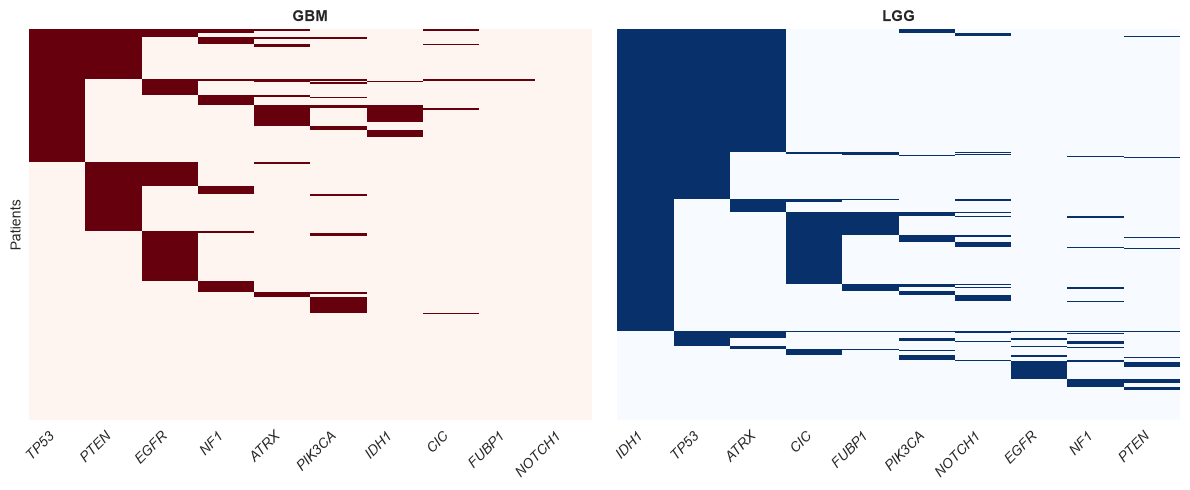

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5),
                         gridspec_kw={"width_ratios": [1, 1]})

for ax, df, cmap, label in [(axes[0], gbm_df, "Reds", "GBM"),
                            (axes[1], lgg_df, "Blues", "LGG")]:
    mut = df[[c for c in df.columns if c.endswith("_mut")]].copy()
    mut.columns = [c.replace("_mut", "") for c in mut.columns]
    order = mut.mean().sort_values(ascending=False).index
    mut = mut[order].sort_values(by=list(order), ascending=False)
    sns.heatmap(mut, cmap=cmap, cbar=False, yticklabels=False, ax=ax, vmin=0, vmax=1)
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Patients" if label == "GBM" else "")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontstyle="italic")

plt.tight_layout()
plt.show()

In [10]:
gbm_mut = gbm_df[[c for c in gbm_df.columns if c.endswith("_mut")]]
lgg_mut = lgg_df[[c for c in lgg_df.columns if c.endswith("_mut")]]

freq = pd.DataFrame({
    "GBM": gbm_mut.mean() * 100,
    "LGG": lgg_mut.mean() * 100,
})
freq.index = [g.replace("_mut", "") for g in freq.index]
freq = freq.loc[freq.mean(axis=1).sort_values(ascending=False).index]
freq_long = freq.reset_index(names="Gene").melt(id_vars="Gene", var_name="Tumour Type",
                                                 value_name="Frequency (%)")

counts = pd.DataFrame({
    "Mutated Genes": pd.concat([gbm_mut.sum(axis=1), lgg_mut.sum(axis=1)]).astype(int).values,
    "Tumour Type": ["GBM"] * len(gbm_mut) + ["LGG"] * len(lgg_mut),
})

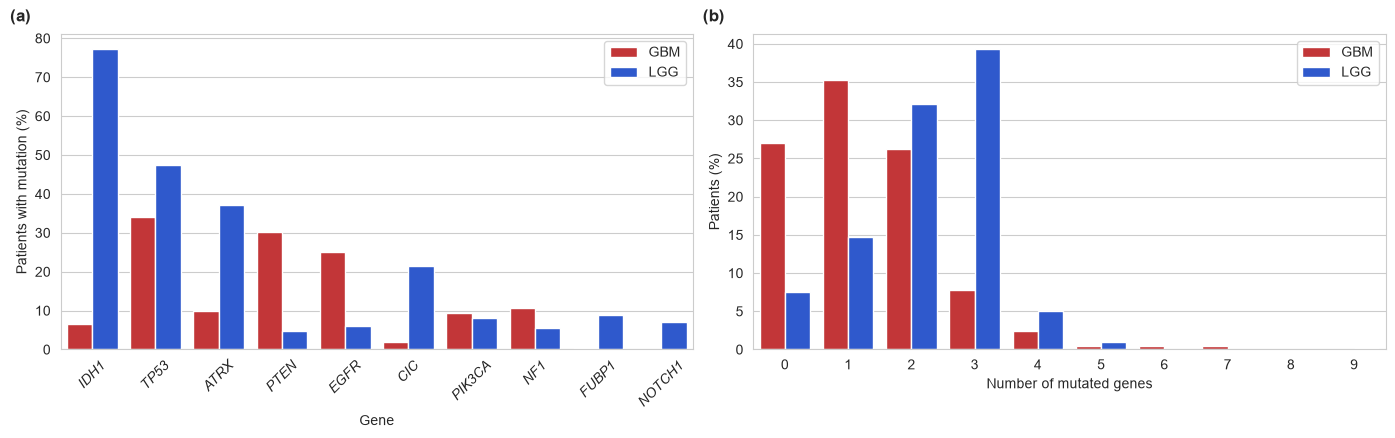

In [11]:
count_pct = (counts.groupby("Tumour Type")["Mutated Genes"].value_counts(normalize=True)
             .mul(100).rename("Frequency (%)").reset_index())

palette = {"GBM": "#D91F22", "LGG": "#154DE6"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(data=freq_long, x="Gene", y="Frequency (%)", hue="Tumour Type",
            palette=palette, ax=axes[0])
axes[0].set_xlabel("Gene")
axes[0].set_ylabel("Patients with mutation (%)")
axes[0].tick_params(axis="x", rotation=45)
for label in axes[0].get_xticklabels():
    label.set_fontstyle("italic")

sns.barplot(data=count_pct, x="Mutated Genes", y="Frequency (%)", hue="Tumour Type",
            order=list(range(counts["Mutated Genes"].max() + 1)), palette=palette, ax=axes[1])
axes[1].set_xlabel("Number of mutated genes")
axes[1].set_ylabel("Patients (%)")

for ax, letter in zip(axes, ["(a)", "(b)"]):
    ax.legend(title=None)
    ax.text(-0.08, 1.04, letter, transform=ax.transAxes, fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

## Gene Expression

In [12]:
gbm_exp_cols = [col for col in gbm_df.columns if col.endswith("_exp")]
lgg_exp_cols = [col for col in lgg_df.columns if col.endswith("_exp")]

gbm_expression_df = gbm_df[gbm_exp_cols]
lgg_expression_df = lgg_df[lgg_exp_cols]

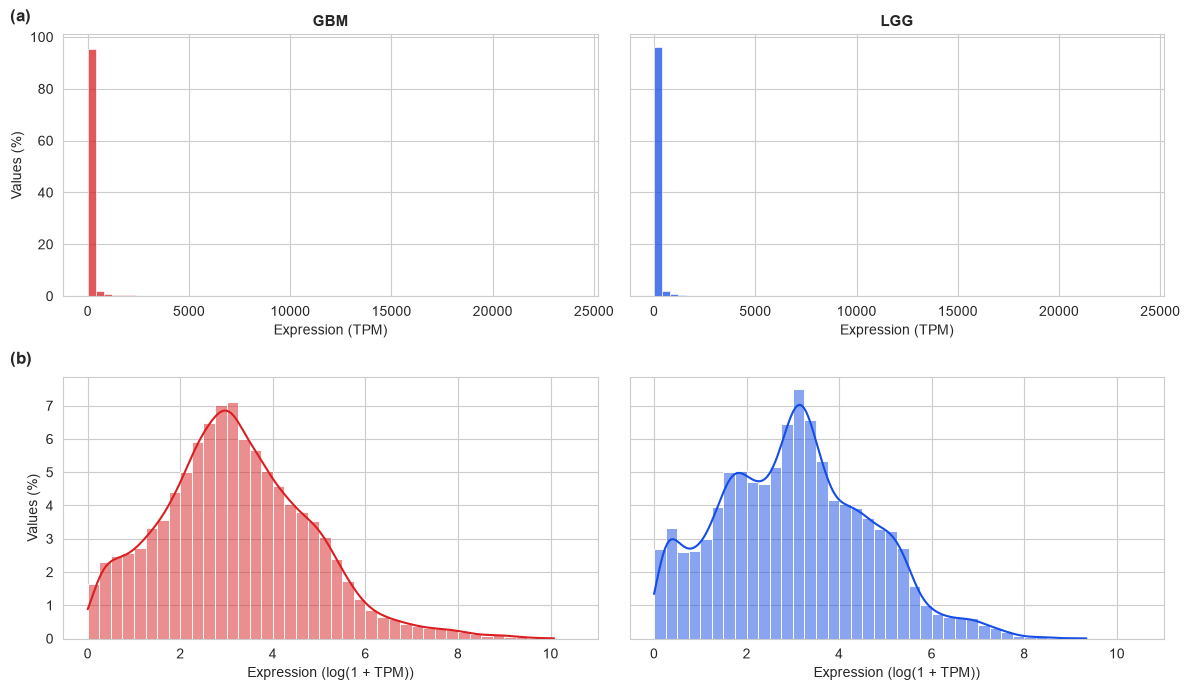

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="row", sharey="row")

raw_bins = np.linspace(0, 24000, 61)
log_bins = np.linspace(0, 10.5, 43)

for col, (df, colour, label) in enumerate([(gbm_df, "#D91F22", "GBM"),
                                           (lgg_df, "#154DE6", "LGG")]):
    log_vals = df[[c for c in df.columns if c.endswith("_exp")]].values.ravel()
    raw_vals = np.expm1(log_vals)

    sns.histplot(raw_vals, bins=raw_bins, stat="percent", color=colour, ax=axes[0, col])
    axes[0, col].set_title(label, fontsize=11, fontweight="bold")
    axes[0, col].set_xlabel("Expression (TPM)")

    sns.histplot(log_vals, bins=log_bins, stat="percent", kde=True, color=colour, ax=axes[1, col])
    axes[1, col].set_xlabel("Expression (log(1 + TPM))")

for row in range(2):
    axes[row, 0].set_ylabel("Values (%)")
    axes[row, 1].set_ylabel("")

axes[0, 0].text(-0.1, 1.05, "(a)", transform=axes[0, 0].transAxes, fontsize=12, fontweight="bold")
axes[1, 0].text(-0.1, 1.05, "(b)", transform=axes[1, 0].transAxes, fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

# Association Analysis

## Within-layer Association Analysis

### Clinical

In [14]:
gbm_t, gbm_p = ttest_ind(gbm_df[gbm_df["gender"] == 0]["age"],
                          gbm_df[gbm_df["gender"] == 1]["age"], equal_var=False)
lgg_t, lgg_p = ttest_ind(lgg_df[lgg_df["gender"] == 0]["age"],
                          lgg_df[lgg_df["gender"] == 1]["age"], equal_var=False)
print(f"GBM: t={gbm_t:.3f}, p={gbm_p:.3f}")
print(f"LGG: t={lgg_t:.3f}, p={lgg_p:.3f}")

GBM: t=0.073, p=0.942
LGG: t=-0.687, p=0.493


### Somatic Mutation

In [15]:
gbm_common_muts = gbm_mutation_df.sum()[gbm_mutation_df.sum() >= 5].index
gbm_mut_filtered = gbm_mutation_df[gbm_common_muts]
gbm_co_occurrence = gbm_mut_filtered.T.dot(gbm_mut_filtered)
gbm_corr_matrix, _ = spearmanr(gbm_mut_filtered)
gbm_corr_df = pd.DataFrame(gbm_corr_matrix, index=gbm_common_muts, columns=gbm_common_muts)

lgg_common_muts = lgg_mutation_df.sum()[lgg_mutation_df.sum() >= 5].index
lgg_mut_filtered = lgg_mutation_df[lgg_common_muts]
lgg_co_occurrence = lgg_mut_filtered.T.dot(lgg_mut_filtered)
lgg_corr_matrix, _ = spearmanr(lgg_mut_filtered)
lgg_corr_df = pd.DataFrame(lgg_corr_matrix, index=lgg_common_muts, columns=lgg_common_muts)

gbm_clean = [c.replace('_mut', '').upper() for c in gbm_common_muts]

In [16]:
lgg_clean = [c.replace('_mut', '').upper() for c in lgg_common_muts]

gbm_co_display = gbm_co_occurrence.copy(); gbm_co_display.index = gbm_co_display.columns = gbm_clean
lgg_co_display = lgg_co_occurrence.copy(); lgg_co_display.index = lgg_co_display.columns = lgg_clean
gbm_corr_display = gbm_corr_df.copy(); gbm_corr_display.index = gbm_corr_display.columns = gbm_clean
lgg_corr_display = lgg_corr_df.copy(); lgg_corr_display.index = lgg_corr_display.columns = lgg_clean

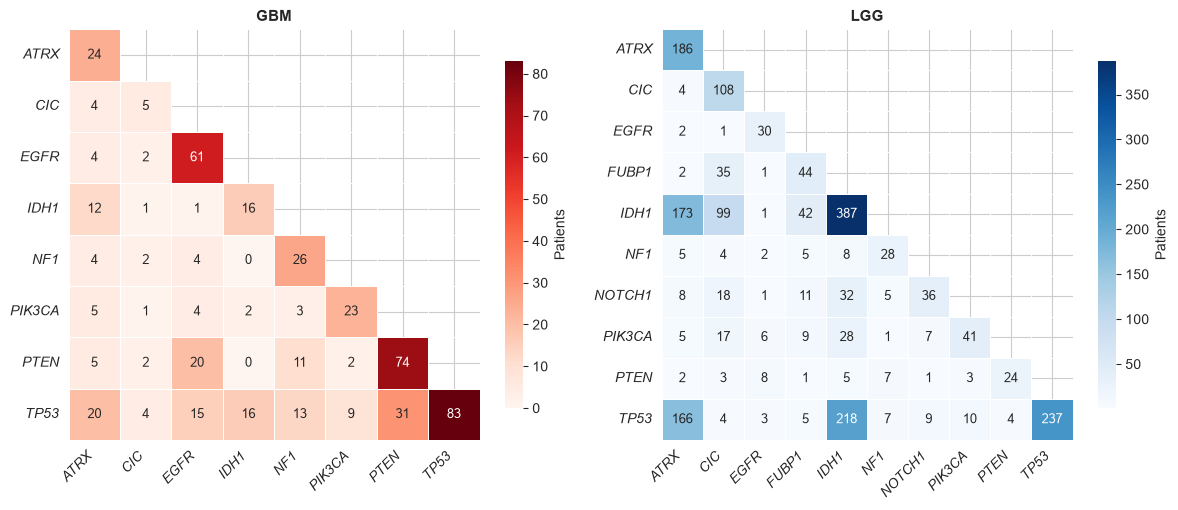

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, counts, cmap, label in [(axes[0], gbm_co_display, "Reds", "GBM"),
                                (axes[1], lgg_co_display, "Blues", "LGG")]:
    mask = np.triu(np.ones_like(counts, dtype=bool), k=1)
    sns.heatmap(counts, mask=mask, annot=True, fmt="d", annot_kws={"size": 9},
                cmap=cmap, square=True, linewidths=0.5,
                cbar_kws={"label": "Patients", "shrink": 0.8}, ax=ax)
    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontstyle="italic")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontstyle="italic")

plt.tight_layout()
plt.show()

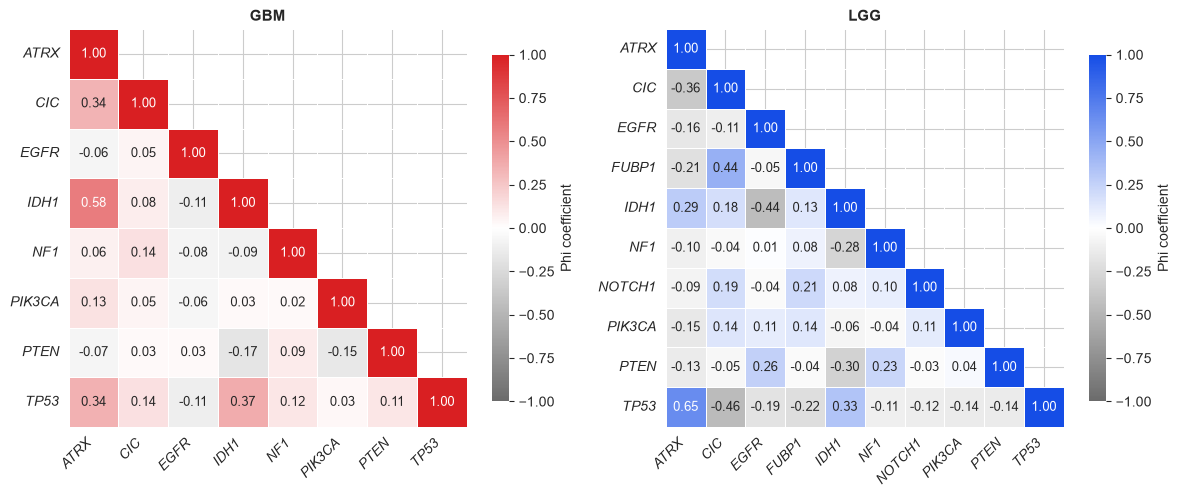

In [18]:
cmaps = {
    "GBM": LinearSegmentedColormap.from_list("gbm_div", ["#6b6b6b", "white", "#D91F22"]),
    "LGG": LinearSegmentedColormap.from_list("lgg_div", ["#6b6b6b", "white", "#154DE6"]),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, corr, label in [(axes[0], gbm_corr_display, "GBM"),
                        (axes[1], lgg_corr_display, "LGG")]:
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 9},
                cmap=cmaps[label], center=0, vmin=-1, vmax=1, square=True,
                linewidths=0.5, cbar_kws={"label": "Phi coefficient", "shrink": 0.8}, ax=ax)
    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontstyle="italic")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontstyle="italic")

plt.tight_layout()
plt.show()

### Gene Expression

In [19]:
gbm_top_var = gbm_expression_df.var().sort_values(ascending=False).head(30).index
lgg_top_var = lgg_expression_df.var().sort_values(ascending=False).head(30).index

gbm_expr_top = gbm_expression_df[gbm_top_var]
lgg_expr_top = lgg_expression_df[lgg_top_var]

gbm_corr_df = gbm_expr_top.corr(method='pearson')
lgg_corr_df = lgg_expr_top.corr(method='pearson')

gbm_corr_display = gbm_corr_df.copy()
gbm_corr_display.index = gbm_corr_display.columns = [c.replace('_exp', '') for c in gbm_expr_top.columns]

lgg_corr_display = lgg_corr_df.copy()

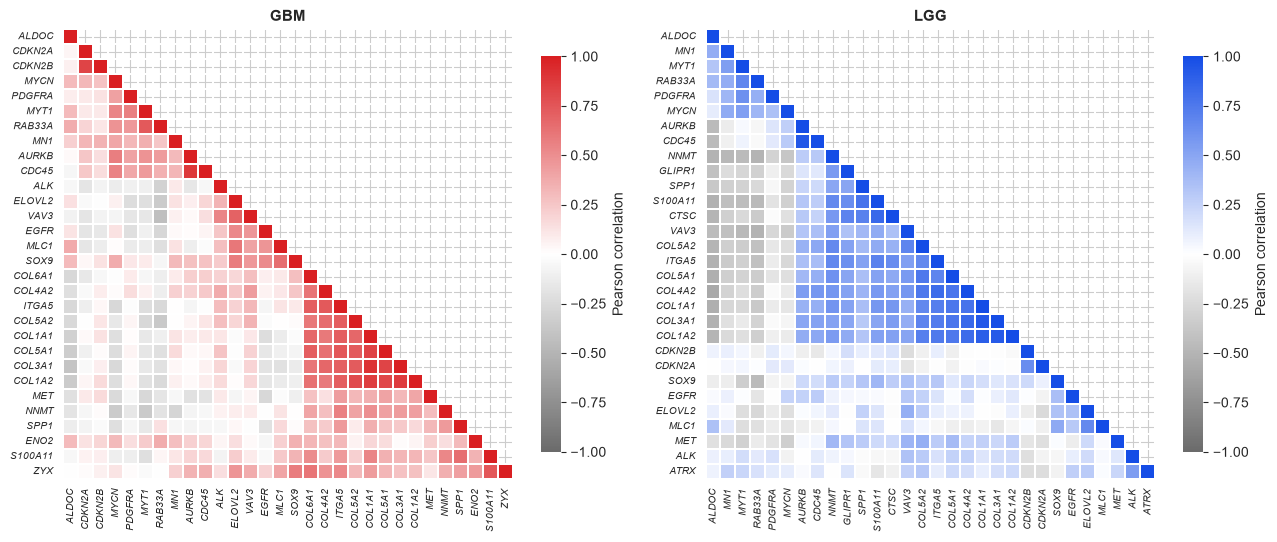

In [20]:
cmaps = {
    "GBM": LinearSegmentedColormap.from_list("gbm_div", ["#6b6b6b", "white", "#D91F22"]),
    "LGG": LinearSegmentedColormap.from_list("lgg_div", ["#6b6b6b", "white", "#154DE6"]),
}

def cluster_order(corr):
    return corr.index[leaves_list(linkage(corr.values, method="average"))]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, expr_top, label in [(axes[0], gbm_expr_top, "GBM"),
                            (axes[1], lgg_expr_top, "LGG")]:
    corr = expr_top.corr(method="pearson")
    corr.index = corr.columns = [c.replace("_exp", "") for c in corr.columns]
    order = cluster_order(corr)
    corr = corr.loc[order, order]
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    sns.heatmap(corr, mask=mask, cmap=cmaps[label], center=0, vmin=-1, vmax=1, square=True,
                linewidths=0.3, xticklabels=True, yticklabels=True,
                cbar_kws={"label": "Pearson correlation", "shrink": 0.7}, ax=ax)
    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=7, fontstyle="italic")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=7, fontstyle="italic")

plt.tight_layout()
plt.show()

## Association with Survival Outcomes

### Clinical

In [21]:
gender_map = {0: "Male", 1: "Female"}
event_map  = {0: "Censored", 1: "Event"}

ct_gbm = pd.crosstab(gbm_df["event"].map(event_map), gbm_df["gender"].map(gender_map))
ct_lgg = pd.crosstab(lgg_df["event"].map(event_map), lgg_df["gender"].map(gender_map))
chi2_gbm, p_gender_gbm, _, _ = chi2_contingency(ct_gbm)
chi2_lgg, p_gender_lgg, _, _ = chi2_contingency(ct_lgg)
_, p_age_gbm = mannwhitneyu(gbm_df.loc[gbm_df["event"]==0,"age"], gbm_df.loc[gbm_df["event"]==1,"age"], alternative="two-sided")
_, p_age_lgg = mannwhitneyu(lgg_df.loc[lgg_df["event"]==0,"age"], lgg_df.loc[lgg_df["event"]==1,"age"], alternative="two-sided")
u_gbm, p_gender_time_gbm = mannwhitneyu(gbm_df.loc[gbm_df["gender"]==0,"time"], gbm_df.loc[gbm_df["gender"]==1,"time"], alternative="two-sided")
u_lgg, p_gender_time_lgg = mannwhitneyu(lgg_df.loc[lgg_df["gender"]==0,"time"], lgg_df.loc[lgg_df["gender"]==1,"time"], alternative="two-sided")
rho_gbm, p_age_time_gbm = spearmanr(gbm_df["age"], gbm_df["time"])

In [22]:
rho_lgg, p_age_time_lgg = spearmanr(lgg_df["age"], lgg_df["time"])

print(f"Event by Sex:  GBM χ²={chi2_gbm:.2f}, p={p_gender_gbm:.3f}  |  LGG χ²={chi2_lgg:.2f}, p={p_gender_lgg:.3f}")
print(f"Age vs Event:     GBM p={p_age_gbm:.3f}  |  LGG p={p_age_lgg:.3f}")
print(f"Time by Sex:   GBM U={u_gbm:.1f}, p={p_gender_time_gbm:.3f}  |  LGG U={u_lgg:.1f}, p={p_gender_time_lgg:.3f}")
print(f"Age vs Time:      GBM r={rho_gbm:.3f}, p={p_age_time_gbm:.3f}  |  LGG r={rho_lgg:.3f}, p={p_age_time_lgg:.3f}")

Event by Sex:  GBM χ²=0.27, p=0.600  |  LGG χ²=1.08, p=0.298
Age vs Event:     GBM p=0.070  |  LGG p=0.000
Time by Sex:   GBM U=7076.5, p=0.919  |  LGG U=30879.0, p=0.942
Age vs Time:      GBM r=-0.244, p=0.000  |  LGG r=-0.086, p=0.053


In [23]:
gbm_age, lgg_age = 60, 40

In [24]:
def lr(df, mask):
    return logrank_test(df.loc[mask, "time"], df.loc[~mask, "time"],
                        event_observed_A=df.loc[mask, "event"],
                        event_observed_B=df.loc[~mask, "event"])

In [25]:
gbm_lr_age    = lr(gbm_df, gbm_df["age"] < gbm_age)
lgg_lr_age    = lr(lgg_df, lgg_df["age"] < lgg_age)
gbm_lr_gender = lr(gbm_df, gbm_df["gender"] == 0)
lgg_lr_gender = lr(lgg_df, lgg_df["gender"] == 0)

print(f"KM by Age  -  GBM: p={gbm_lr_age.p_value:.3f}  |  LGG: p={lgg_lr_age.p_value:.3f}")
print(f"KM by Sex  -  GBM: p={gbm_lr_gender.p_value:.3f}  |  LGG: p={lgg_lr_gender.p_value:.3f}")

cohorts = [
    ("GBM", gbm_df, gbm_age, "#D91F22", "#EC8F90"),
    ("LGG", lgg_df, lgg_age, "#154DE6", "#8FA6F2"),
]

KM by Age  -  GBM: p=0.004  |  LGG: p=0.000
KM by Sex  -  GBM: p=0.317  |  LGG: p=0.728


In [26]:
def plot_km_by(variable):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, (name, df, cut, dark, light) in zip(axes, cohorts):
        if variable == "sex":
            groups = [(df["gender"] == 0, "Male", dark),
                      (df["gender"] == 1, "Female", light)]
        else:
            groups = [(df["age"] < cut,  f"<{cut} years", light),
                      (df["age"] >= cut, f"≥{cut} years", dark)]
        for mask, label, colour in groups:
            KaplanMeierFitter().fit(df.loc[mask, "time"], df.loc[mask, "event"], label=label
            ).plot_survival_function(ax=ax, ci_show=False, color=colour, lw=2)
        ax.set_title(name, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylim(0, 1.05)
        ax.legend(frameon=False, loc="upper right")
    axes[0].set_ylabel("Survival probability")
    fig.supxlabel("Time (days)")
    plt.tight_layout()
    plt.show()

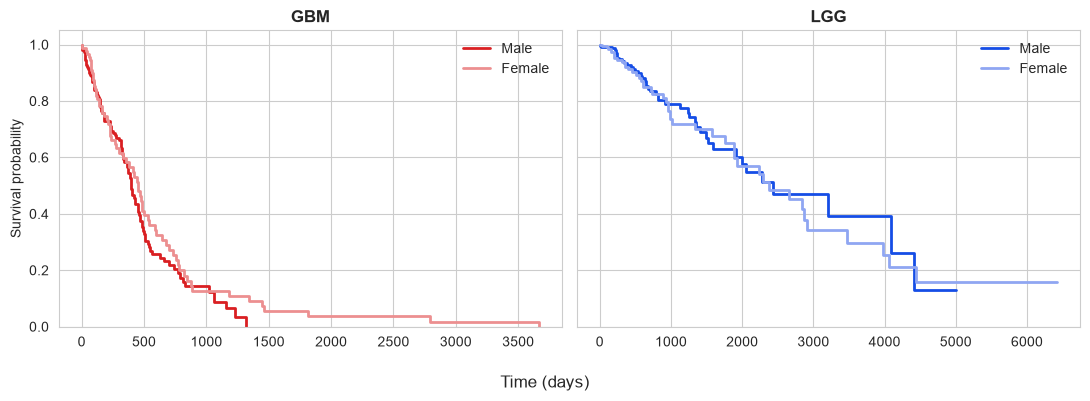

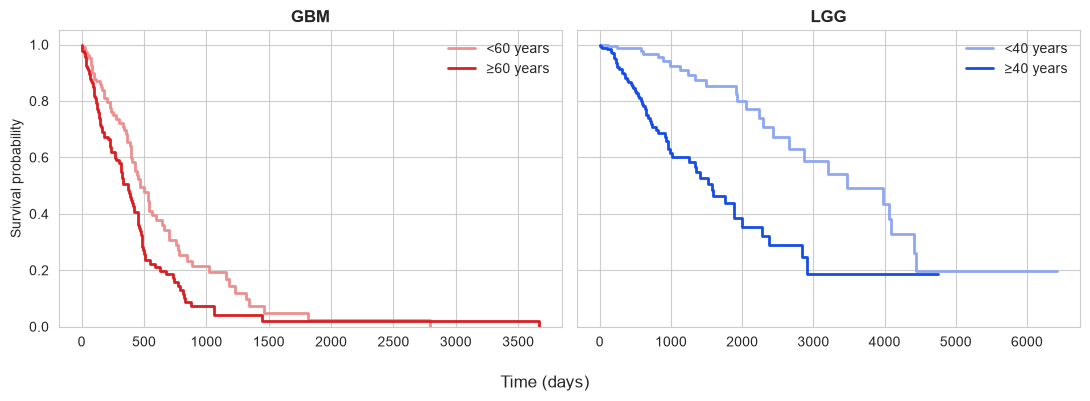

In [27]:
plot_km_by("sex")
plot_km_by("age")

### Somatic Mutation

GBM IDH1: log-rank p = 0.00126
GBM TP53: log-rank p = 0.0112


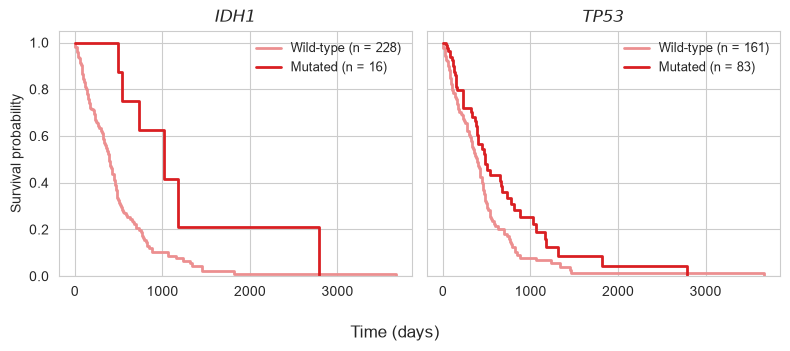

LGG IDH1: log-rank p = 6.6e-09
LGG CIC: log-rank p = 0.00786
LGG EGFR: log-rank p = 9.54e-07


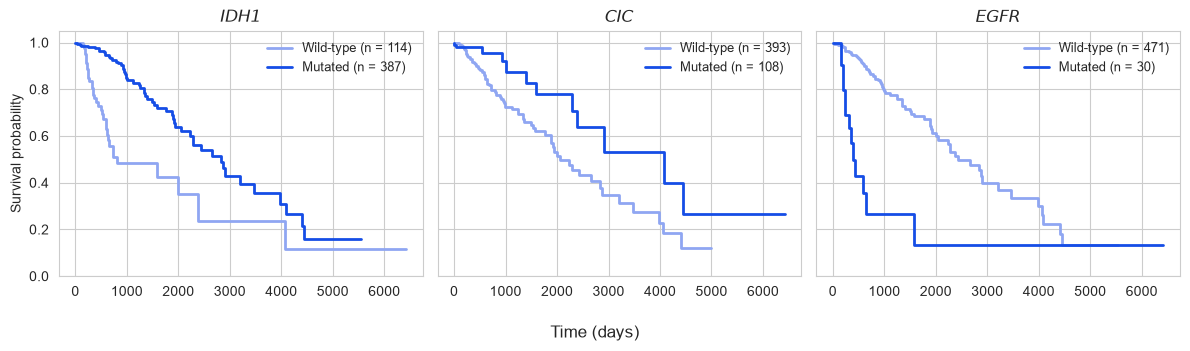

In [28]:
km_genes = {
    "GBM": (gbm_df, ["IDH1", "TP53"],        "#D91F22", "#EC8F90"),
    "LGG": (lgg_df, ["IDH1", "CIC", "EGFR"], "#154DE6", "#8FA6F2"),
}

def plot_km_mutations(name):
    df, genes, dark, light = km_genes[name]
    fig, axes = plt.subplots(1, len(genes), figsize=(4 * len(genes), 3.5), sharey=True, sharex=True)
    for ax, gene in zip(axes, genes):
        col = f"{gene}_mut"
        lr = logrank_test(df.loc[df[col] == 0, "time"], df.loc[df[col] == 1, "time"],
                          event_observed_A=df.loc[df[col] == 0, "event"],
                          event_observed_B=df.loc[df[col] == 1, "event"])
        print(f"{name} {gene}: log-rank p = {lr.p_value:.3g}")
        for val, label, colour in [(0, "Wild-type", light), (1, "Mutated", dark)]:
            m = df[col] == val
            KaplanMeierFitter().fit(df.loc[m, "time"], df.loc[m, "event"],
                                    label=f"{label} (n = {m.sum()})"
            ).plot_survival_function(ax=ax, ci_show=False, color=colour, lw=2)
        ax.set_title(f"$\\it{{{gene}}}$", fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylim(0, 1.05)
        ax.legend(frameon=False, loc="upper right", fontsize=9)
    axes[0].set_ylabel("Survival probability")
    fig.supxlabel("Time (days)")
    plt.tight_layout()
    plt.show()

plot_km_mutations("GBM")
plot_km_mutations("LGG")

# Dimensionality Reduction

## Gene Expression

### Pathway Gene Analysis

In [29]:
gbm_scores_df = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_gbm\dimred_merged_df.csv")
lgg_scores_df = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_lgg\dimred_merged_df.csv")

In [30]:
g2m_genes         = ["AURKB_exp", "RPA2_exp", "MCM5_exp", "CDC45_exp", "MCM6_exp"]
pi3k_mtor_genes   = ['MAPK1_exp', 'MAPK8_exp', 'MAP3K7_exp', 'MAP2K6_exp', 'MAPK9_exp']
hypoxia_genes     = ['ALDOC_exp', 'ALDOB_exp', 'ENO2_exp', 'ENO3_exp', 'PFKP_exp']
emt_genes         = ['COL1A2_exp', 'COL1A1_exp', 'COL5A1_exp', 'COL3A1_exp', 'COL4A2_exp']
mesenchymal_genes = ['ARPC1B_exp', 'S100A11_exp', 'CTSC_exp', 'GLIPR1_exp', 'NNMT_exp']
proneural_genes   = ['RAB33A_exp', 'HDAC2_exp', 'MYT1_exp', 'MTSS1_exp']
classical_genes   = ['PTPRA_exp', 'ELOVL2_exp', 'MLC1_exp', 'SOX9_exp', 'ARNTL_exp']
farg_genes        = ['RAP1B_exp', 'VAV3_exp', 'ZYX_exp', 'COL5A2_exp', 'SPP1_exp',
                     'COL6A1_exp', 'ITGA5_exp', 'SHC1_exp']

In [31]:
pathway_gene_map = {
    "G2M Pathway":          g2m_genes,
    "PI3K mTOR Pathway":    pi3k_mtor_genes,
    "Hypoxia Pathway":      hypoxia_genes,
    "EMT Pathway":          emt_genes,
    "Mesenchymal Pathway":  mesenchymal_genes,
    "Proneural Pathway":    proneural_genes,
    "Classical Pathway":    classical_genes,
    "FARG Pathway":         farg_genes,
}

score_label_map = {
    'g2m':           'G2M',
    'pi3k_akt_mtor': 'PI3K/AKT/mTOR',
    'hypoxia':       'Hypoxia',
    'emt':           'EMT',
    'mesenchymal':   'Mesenchymal',
    'proneural':     'Proneural',
    'classical':     'Classical',
    'farg':          'FARG',
}

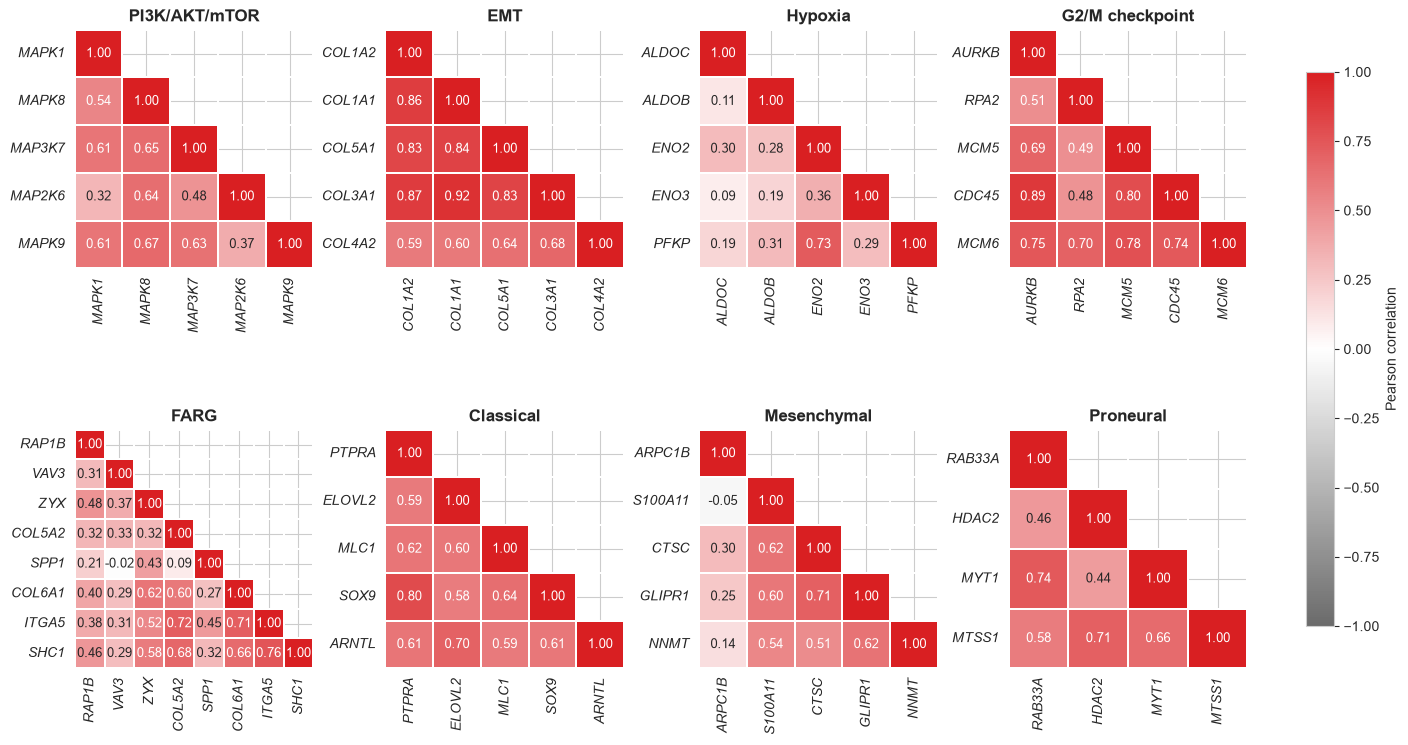

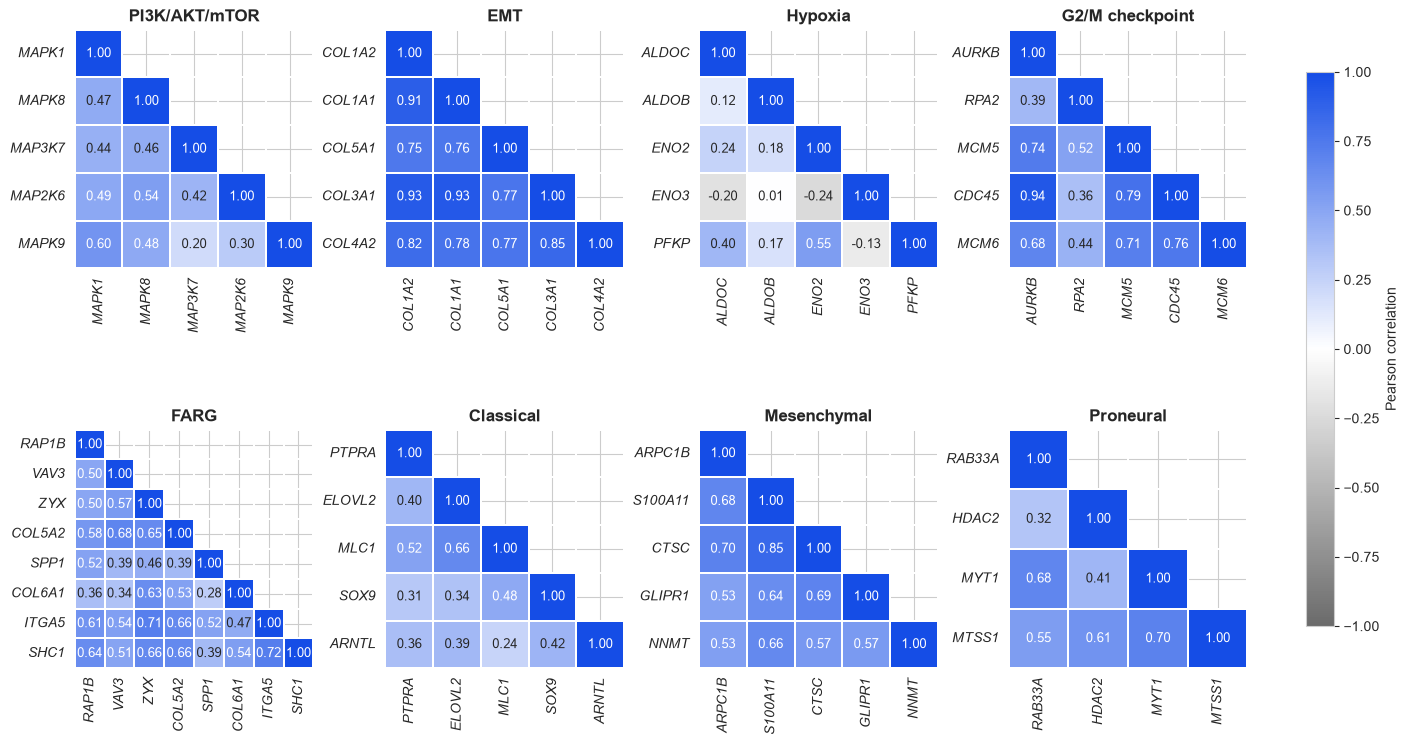

In [32]:
gene_sets = {
    "PI3K/AKT/mTOR":   ["MAPK1", "MAPK8", "MAP3K7", "MAP2K6", "MAPK9"],
    "EMT":             ["COL1A2", "COL1A1", "COL5A1", "COL3A1", "COL4A2"],
    "Hypoxia":         ["ALDOC", "ALDOB", "ENO2", "ENO3", "PFKP"],
    "G2/M checkpoint": ["AURKB", "RPA2", "MCM5", "CDC45", "MCM6"],
    "FARG":            ["RAP1B", "VAV3", "ZYX", "COL5A2", "SPP1", "COL6A1", "ITGA5", "SHC1"],
    "Classical":       ["PTPRA", "ELOVL2", "MLC1", "SOX9", "ARNTL"],
    "Mesenchymal":     ["ARPC1B", "S100A11", "CTSC", "GLIPR1", "NNMT"],
    "Proneural":       ["RAB33A", "HDAC2", "MYT1", "MTSS1"],
}

for label, expr_df in [("GBM", gbm_expression_df), ("LGG", lgg_expression_df)]:
    fig, axes = plt.subplots(2, 4, figsize=(14, 8), layout="constrained")

    for ax, (title, genes) in zip(axes.flat, gene_sets.items()):
        cols = [f"{g}_exp" for g in genes if f"{g}_exp" in expr_df.columns]
        corr = expr_df[cols].corr(method="pearson")
        corr.index = corr.columns = [c.replace("_exp", "") for c in cols]
        mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

        sns.heatmap(corr, mask=mask, cmap=cmaps[label], center=0, vmin=-1, vmax=1, square=True,
                    linewidths=0.3, annot=True, fmt=".2f", annot_kws={"size": 9},
                    cbar=False, ax=ax)
        ax.set_title(title, fontsize=12, fontweight="bold")
        ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=10, fontstyle="italic")
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10, fontstyle="italic")

    fig.colorbar(axes.flat[0].collections[0], ax=axes, shrink=0.7, label="Pearson correlation")
    plt.show()

### Pathway Score Distribution

In [33]:
gbm_score_cols = [col for col in gbm_scores_df.columns if col.endswith("_score_exp")]
lgg_score_cols = [col for col in lgg_scores_df.columns if col.endswith("_score_exp")]
all_score_cols = gbm_score_cols + [col for col in lgg_score_cols if col not in gbm_score_cols]

In [34]:
score_labels = {
    "pi3k_akt_mtor_score_exp": "PI3K/AKT/mTOR",
    "emt_score_exp":           "EMT",
    "hypoxia_score_exp":       "Hypoxia",
    "g2m_score_exp":           "G2/M checkpoint",
    "farg_score_exp":          "FARG",
    "classical_score_exp":     "Classical",
    "mesenchymal_score_exp":   "Mesenchymal",
    "proneural_score_exp":     "Proneural",
}

bins = np.linspace(-4.5, 4.5, 31)

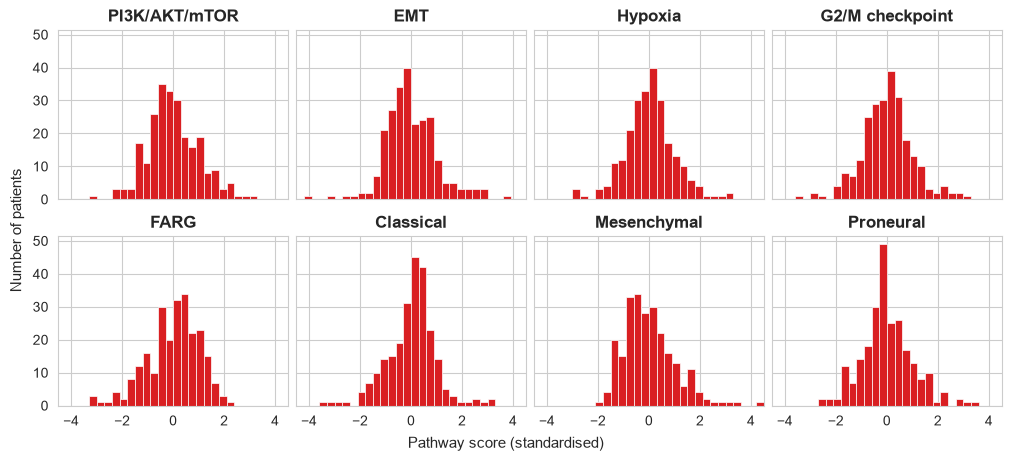

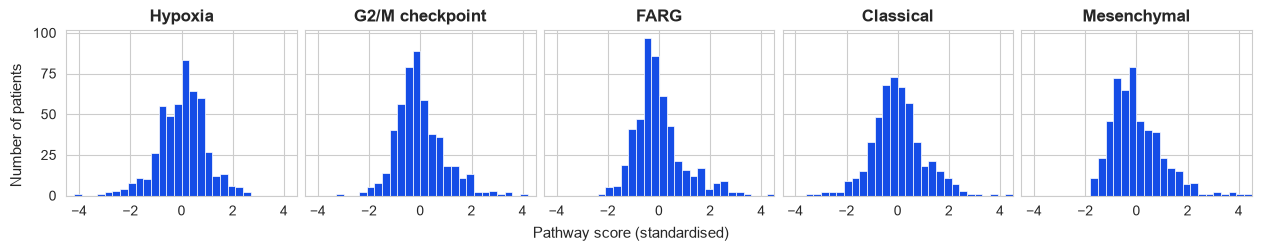

In [35]:
for label, df, colour, nrows, ncols, figsize in [
    ("GBM", gbm_scores_df, "#D91F22", 2, 4, (10, 4.5)),
    ("LGG", lgg_scores_df, "#154DE6", 1, 5, (12.5, 2.4)),
]:
    cols = [c for c in score_labels if c in df.columns]
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharex=True, sharey=True,
                             layout="constrained")

    for ax, col in zip(axes.flat, cols):
        ax.hist(df[col].dropna(), bins=bins, color=colour, edgecolor="white", linewidth=0.5)
        ax.set_title(score_labels[col], fontsize=12, fontweight="bold")
        ax.set_xlim(-4.5, 4.5)
        ax.set_xticks([-4, -2, 0, 2, 4])
        ax.tick_params(labelsize=10)

    fig.supxlabel("Pathway score (standardised)", fontsize=11)
    fig.supylabel("Number of patients", fontsize=11)
    plt.show()

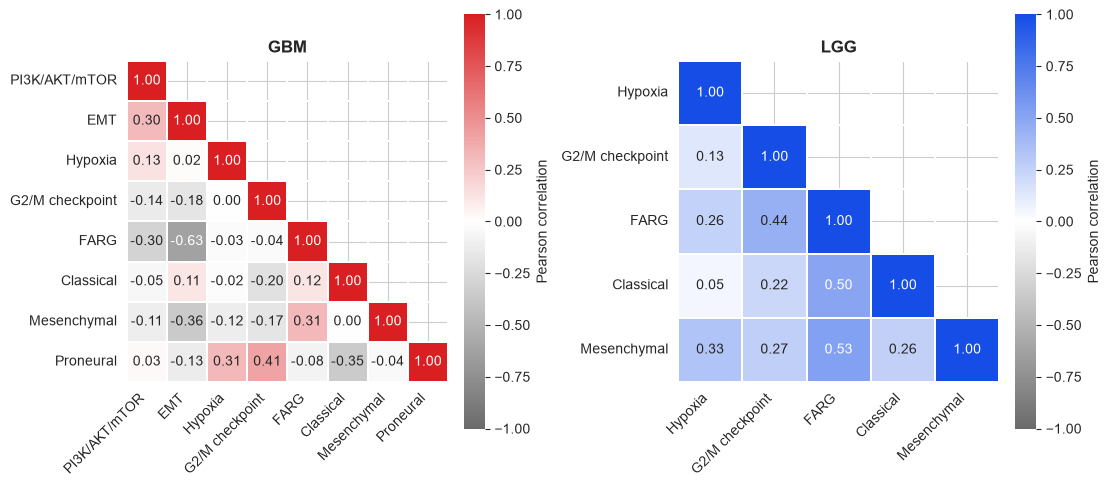

In [36]:
score_labels = {
    "pi3k_akt_mtor_score_exp": "PI3K/AKT/mTOR",
    "emt_score_exp":           "EMT",
    "hypoxia_score_exp":       "Hypoxia",
    "g2m_score_exp":           "G2/M checkpoint",
    "farg_score_exp":          "FARG",
    "classical_score_exp":     "Classical",
    "mesenchymal_score_exp":   "Mesenchymal",
    "proneural_score_exp":     "Proneural",
}

fig, axes = plt.subplots(1, 2, figsize=(11, 6), layout="constrained")

for ax, df, label in [(axes[0], gbm_scores_df, "GBM"), (axes[1], lgg_scores_df, "LGG")]:
    cols = [c for c in score_labels if c in df.columns]
    corr = df[cols].corr(method="pearson")
    corr.index = corr.columns = [score_labels[c] for c in cols]
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    sns.heatmap(corr, mask=mask, cmap=cmaps[label], center=0, vmin=-1, vmax=1, square=True,
                linewidths=0.3, annot=True, fmt=".2f", annot_kws={"size": 10},
                cbar_kws={"label": "Pearson correlation", "shrink": 0.7}, ax=ax)
    ax.set_title(label, fontsize=12, fontweight="bold")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=10)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)

plt.show()

# Model and Method Evaluation

## Performance Summary

In [37]:
val_df_gbm = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_gbm\val_df_gbm.csv")
val_df_lgg = pd.read_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_lgg\val_df_lgg.csv")

val_df_gbm["Tumour"] = "GBM"
val_df_lgg["Tumour"] = "LGG"

combined_df = pd.concat([val_df_gbm, val_df_lgg], ignore_index=True)

In [38]:
display(
    combined_df[["Tumour", "Model", "Feature Set"] +
                [c for c in combined_df.columns if c not in ["Tumour", "Model", "Feature Set"]]]
    .sort_values(["Tumour", "Model", "Feature Set"])
    .reset_index(drop=True)
    .round(3)
    .rename(columns=lambda c: c.replace("LogReg ", "LR ").replace("GBM ", "GBoost "))
)

,Tumour,Model,Feature Set,LR TCGA Test AUC,LR TCGA Test AUC SD,LR TCGA Train AUC,LR CGGA Val AUC,CPH TCGA Test C-index,CPH TCGA Test C-index SD,CPH TCGA Train C-index,...,RSF TCGA Train C-index,RSF CGGA Val C-index,GBoost TCGA Test C-index,GBoost TCGA Test C-index SD,GBoost TCGA Train C-index,GBoost CGGA Val C-index,ANN TCGA Test C-index,ANN TCGA Test C-index SD,ANN TCGA Train C-index,ANN CGGA Val C-index
0,GBM,Model 1,Original,0.578,0.050,0.589,0.607,0.633,0.049,0.628,...,0.657,0.704,0.607,0.066,0.660,0.696,0.640,0.056,0.633,0.691
1,GBM,Model 1,Reduced,0.578,0.050,0.589,0.607,0.633,0.049,0.628,...,0.657,0.704,0.607,0.066,0.660,0.696,0.640,0.056,0.633,0.691
2,GBM,Model 2,Original,0.583,0.073,0.616,0.571,0.644,0.058,0.637,...,0.677,0.604,0.617,0.058,0.685,0.642,0.586,0.054,0.617,0.585
3,GBM,Model 2,Reduced,0.588,0.070,0.620,0.526,0.634,0.049,0.629,...,0.681,0.597,0.626,0.054,0.683,0.621,0.620,0.043,0.635,0.642
4,GBM,Model 3,Original,0.655,0.058,0.745,0.469,0.648,0.024,0.676,...,0.851,0.568,0.604,0.048,0.880,0.584,0.602,0.045,0.768,0.556
5,GBM,Model 3,Reduced,0.499,0.051,0.606,0.638,0.628,0.034,0.645,...,0.748,0.614,0.604,0.050,0.736,0.658,0.589,0.053,0.621,0.504
6,GBM,Model 4,Original,0.644,0.051,0.753,0.423,0.651,0.030,0.700,...,0.825,0.572,0.585,0.054,0.939,0.615,0.637,0.031,0.812,0.540
7,GBM,Model 4,Reduced,0.547,0.055,0.644,0.556,0.637,0.041,0.644,...,0.758,0.586,0.608,0.047,0.763,0.630,0.600,0.033,0.677,0.607
8,LGG,Model 1,Original,0.644,0.071,0.652,0.461,0.786,0.053,0.780,...,0.853,0.469,0.757,0.074,0.819,0.538,0.778,0.063,0.781,0.487
9,LGG,Model 1,Reduced,0.644,0.071,0.652,0.461,0.786,0.053,0.780,...,0.853,0.469,0.757,0.074,0.819,0.538,0.778,0.063,0.781,0.487
